# ЛР №2

Titanic Dataset

План работы:
1. Знакомство с данными (EDA)
2. Подготовка данных и разбиение на train / test
3. Метрики
4. Baseline (Dummy)
5. Модели: Decision Tree, Random Forest, Gradient Boosting, SVM, KNN
6. Итоговая таблица и сравнение моделей
7. Feature importance
8. Анализ ошибок лучшей модели и проверка "подозрительных" признаков
9. Выводы

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import warnings
warnings.simplefilter("ignore")
%matplotlib inline

sns.set(style="darkgrid")

RANDOM_STATE = 42

## 1. Смотрим данные

In [ ]:
data = pd.read_csv("archive/Titanic-Dataset.csv")

print("Размер:", data.shape)
data.head()

Размер: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [ ]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [ ]:
missing = pd.DataFrame({
    "пропусков": data.isnull().sum(),
    "доля": (data.isnull().sum() / len(data)).round(3)
})
missing[missing["пропусков"] > 0]

,пропусков,доля
Age,177,0.199
Cabin,687,0.771
Embarked,2,0.002


In [ ]:
print("Дубликатов:", data.duplicated().sum())
print("Дубликатов без PassengerId:", data.drop(columns=["PassengerId"]).duplicated().sum())

Дубликатов: 0
Дубликатов без PassengerId: 0


In [ ]:
data.nunique()

PassengerId    891
Survived         2
Pclass           3
Name           891
Sex              2
Age             88
SibSp            7
Parch            7
Ticket         681
Fare           248
Cabin          147
Embarked         3
dtype: int64

**Дубликаты и пропуски**
- 891 пассажир, 12 колонок. Дубликатов нет.
- Пропуски есть в 3 признаках:
  - `Age` - около 20% пропусков. Возраст, скорее всего, важен
    пропуски нужно заполнить.
  - `Cabin` - 77% пропусков. Бесполезный признак
  - `Embarked` - 2 пропуска, заполняем самым частым портом.
- Есть текстовые признаки: `Sex`, `Embarked`, `Name`, `Ticket`, `Cabin`. Нужно перевести в числа.

**Плохие признаки**
- `PassengerId` - не несёт никакой информации о пассажире, но уникален у каждого.
- `Name` - идентификатор человека. Из имени можно достать обращение (Mr, Mrs, Miss, Master) - полезная информация о поле, возрасте и семейном положении.
- `Ticket` - 681 из 891 уникально. Одинаковый билет бывает только у людей из одной
  семьи или компании. Бесполезный признак
- `Cabin` — очень много пропусков, непонятно как заполнять

### Целевая переменная

Survived
0    549
1    342
Name: count, dtype: int64

Survived
0    0.616
1    0.384
Name: proportion, dtype: float64


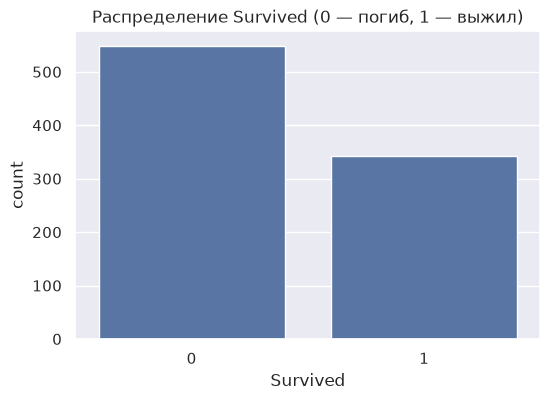

In [ ]:
print(data["Survived"].value_counts())
print()
print(data["Survived"].value_counts(normalize=True).round(3))

plt.figure(figsize=(6, 4))
sns.countplot(x="Survived", data=data)
plt.title("Распределение Survived (0 — погиб, 1 — выжил)")
plt.show()

Выжило около 38% пассажиров, погибло около 62%. Классы немного несбалансированы

Accuracy - 0.62 если всем говорить погиб.


### Выживаемость по разным признакам

Для каждой группы считаем долю выживших

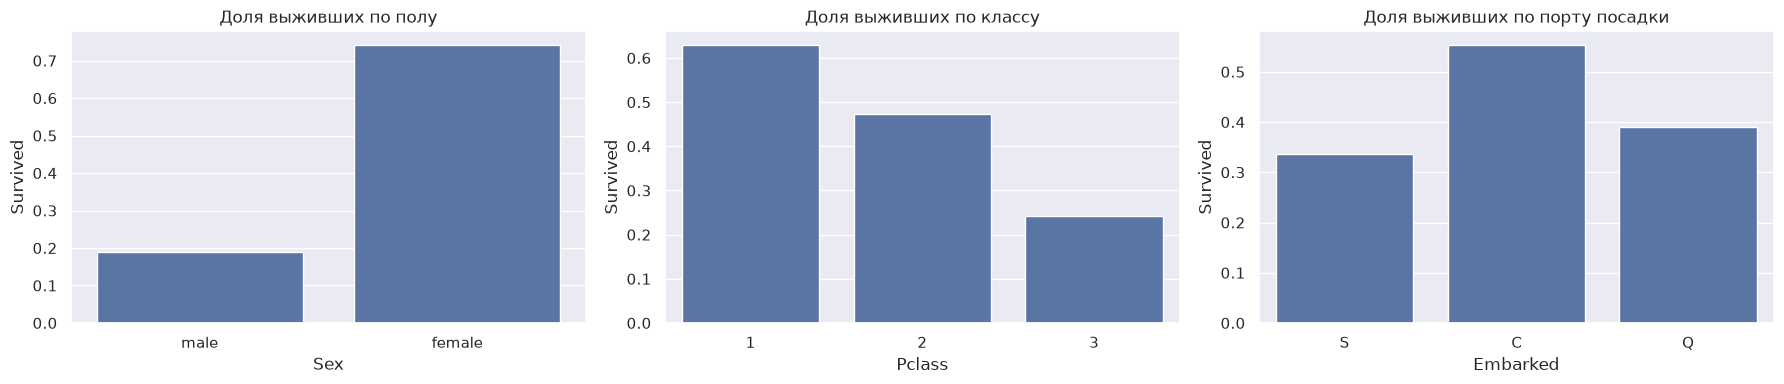

Sex
female    0.742
male      0.189
Name: Survived, dtype: float64
Pclass
1    0.630
2    0.473
3    0.242
Name: Survived, dtype: float64
Embarked
C    0.554
Q    0.390
S    0.337
Name: Survived, dtype: float64


In [8]:
# доля выживших среди мужчин и женщин, а также по классу билета
fig, axs = plt.subplots(1, 3, figsize=(18, 4))

sns.barplot(x="Sex", y="Survived", data=data, ax=axs[0], errorbar=None)
axs[0].set_title("Доля выживших по полу")

sns.barplot(x="Pclass", y="Survived", data=data, ax=axs[1], errorbar=None)
axs[1].set_title("Доля выживших по классу")

sns.barplot(x="Embarked", y="Survived", data=data, ax=axs[2], errorbar=None)
axs[2].set_title("Доля выживших по порту посадки")
plt.tight_layout()
plt.show()

print(data.groupby("Sex")["Survived"].mean().round(3))
print(data.groupby("Pclass")["Survived"].mean().round(3))
print(data.groupby("Embarked")["Survived"].mean().round(3))

In [9]:
# пол и класс вместе: доля выживших и количество людей в каждой группе
data.groupby(["Sex", "Pclass"])["Survived"].agg(["mean", "count"]).round(3)

mean  count
Sex    Pclass              
female 1       0.968     94
       2       0.921     76
       3       0.500    144
male   1       0.369    122
       2       0.157    108
       3       0.135    347

**Выводы:**
- Выжило 74% женщин и только 19% мужчин.
- в 1-м классе выжило 63%, во 2-м — 47%, в 3-м — 24%. 
- женщины из 1-го и 2-го класса выжили почти все (97% и 92%), а женщины из 3-го — только наполовину.
  Мужчины из 2-го и 3-го класса почти все погибли (16% и 14%). Значит, признаки влияют совместно
-из Шербура (C) выжило 55%, из Саутгемптона (S) — 34%. Скорее всего, сам порт ни на что не влияет,
  просто в Шербуре садилось больше пассажиров 1-го класса.

In [ ]:
# состав пассажиров по классам в каждом порту
pd.crosstab(data["Embarked"], data["Pclass"], normalize="index").round(2)

Pclass,1,2,3
Embarked,,,
C,0.51,0.10,0.39
Q,0.03,0.04,0.94
S,0.20,0.25,0.55


в Шербуре (C) половина пассажиров — из 1-го класса, а в Квинстауне (Q) 94% — из 3-го.
Поэтому высокая выживаемость шербурских пассажиров объясняется классом, а не портом.

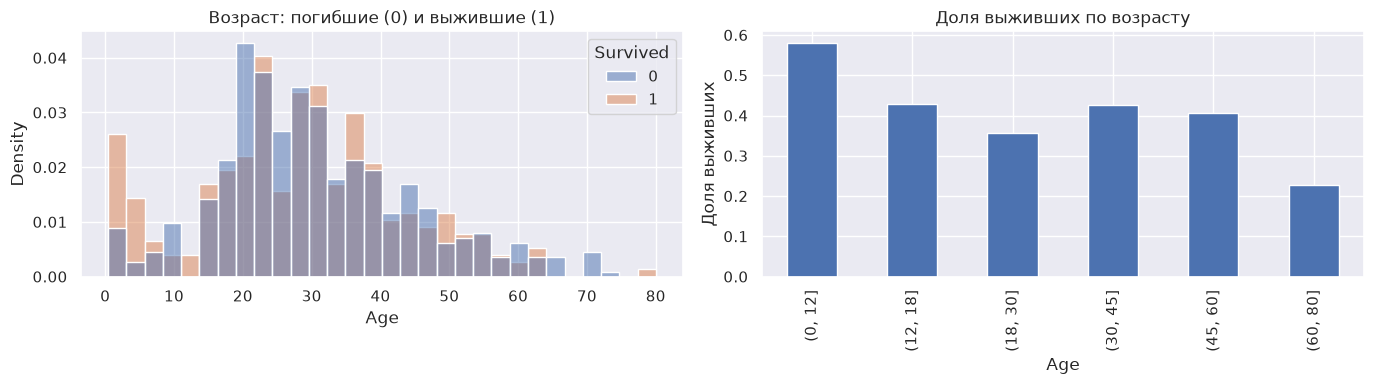

           mean  count
Age                   
(0, 12]   0.580     69
(12, 18]  0.429     70
(18, 30]  0.356    270
(30, 45]  0.426    202
(45, 60]  0.407     81
(60, 80]  0.227     22


In [ ]:
# распределение возраста у погибших и выживших
fig, axs = plt.subplots(1, 2, figsize=(14, 4))

sns.histplot(data=data, x="Age", hue="Survived", bins=30, stat="density", common_norm=False, ax=axs[0])
axs[0].set_title("Возраст: погибшие (0) и выжившие (1)")

age_groups = pd.cut(data["Age"], bins=[0, 12, 18, 30, 45, 60, 80])
data.groupby(age_groups)["Survived"].mean().plot(kind="bar", ax=axs[1])
axs[1].set_title("Доля выживших по возрасту")
axs[1].set_ylabel("Доля выживших")
plt.tight_layout()
plt.show()

print(data.groupby(age_groups)["Survived"].agg(["mean", "count"]).round(3))

**Возраст:** заметнее всего отличаются дети до 12 лет - их выжило 58%, больше, чем в любой другой группе.
У пожилых (60+) выживаемость самая низкая (23%). Между 18 и 60 годами разница небольшая.


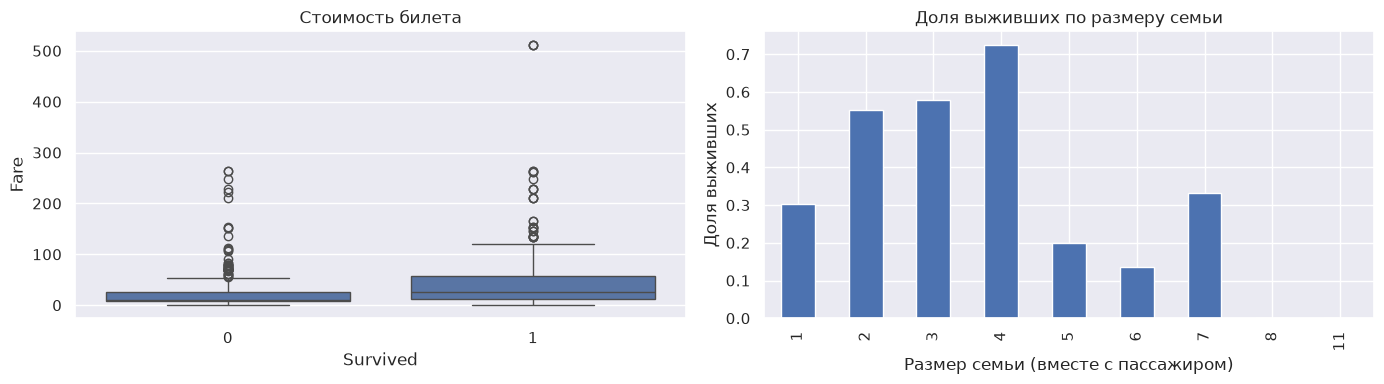

            1        2        3       4     5       6       7    8    11
mean     0.304    0.553    0.578   0.724   0.2   0.136   0.333  0.0  0.0
count  537.000  161.000  102.000  29.000  15.0  22.000  12.000  6.0  7.0


In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(14, 4))

# стоимость билета у погибших и выживших
sns.boxplot(x="Survived", y="Fare", data=data, ax=axs[0])
axs[0].set_title("Стоимость билета")

# размер семьи
family_size = data["SibSp"] + data["Parch"] + 1
data.groupby(family_size)["Survived"].mean().plot(kind="bar", ax=axs[1])
axs[1].set_title("Доля выживших по размеру семьи")
axs[1].set_xlabel("Размер семьи (вместе с пассажиром)")
axs[1].set_ylabel("Доля выживших")
plt.tight_layout()
plt.show()

print(data.groupby(family_size)["Survived"].agg(["mean", "count"]).round(3).T)

**Стоимость билета:** у выживших билеты в среднем дороже. 
дорогие билеты — это 1-й класс. У `Fare` есть сильные выбросы (до 512)

**Размер семьи:** одиночки выживали реже (30%), семьи из 2–4 человек — чаще (55–72%), а большие семьи (5+) почти все
погибли. Тоже нелинейная связь в виде горки.

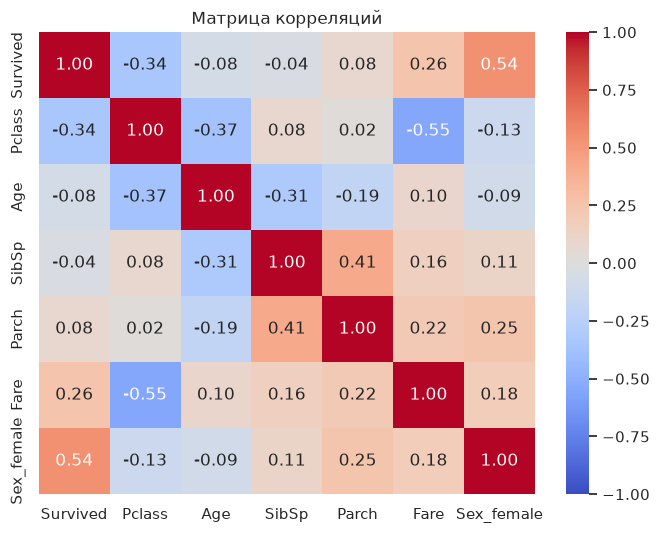

In [ ]:
numeric = data[["Survived", "Pclass", "Age", "SibSp", "Parch", "Fare"]].copy()
numeric["Sex_female"] = (data["Sex"] == "female").astype(int)

plt.figure(figsize=(8, 6))
sns.heatmap(numeric.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Матрица корреляций")
plt.show()

**Корреляции:** сильнее всего с `Survived` связаны пол (+0.54, женщины выживали чаще) и класс (−0.34: чем больше номер класса,
тем ниже выживаемость). `Fare` связан положительно (+0.26), но он сильно коррелирует с `Pclass` (−0.55) —
то есть частично дублирует класс. У `Age`, `SibSp`, `Parch` корреляция почти нулевая, но мы видели, что связь у них
нелинейная (дети, размер семьи), так что выбрасывать их нельзя.

## 2. Подготовка данных и выборок

### 2.1 Новые признаки

- **Title** - обращение из имени. Категория
  из нескольких значений, которая содержит пол, примерный возраст
  и статус. Редкие обращения объединяю в одну группу `Rare`, иначе в некоторых категориях будет по 1 человеку.
- **FamilySize** = `SibSp` + `Parch` + 1 - размер семьи на борту.
- **Sex** 1 - женщина, 0 - мужчина.

In [ ]:
data["Title"] = data["Name"].str.extract(r",\s*([^\.]+)\.")[0]
print(data["Title"].value_counts())

Title
Mr              517
Miss            182
Mrs             125
Master           40
Dr                7
Rev               6
Major             2
Mlle              2
Col               2
Don               1
Mme               1
Ms                1
Lady              1
Sir               1
Capt              1
the Countess      1
Jonkheer          1
Name: count, dtype: int64


выжило 16% `Mr`, но 58% `Master` - это хорошо показывает
правило "дети первыми" даже для мужского пола. `Miss` и `Mrs` выживали в 70–79% случаев.

### 2.2 Все признаки

| Признак | Решение | Почему |
|---|---|---|
| Pclass | оставляем как число | класс упорядочен (1 < 2 < 3), поэтому число подходит |
| Sex | 0/1 | бинарный признак |
| Age | заполняем пропуски медианой | 20% пропусков; медиана устойчива к выбросам |
| Fare | оставляем | связан с классом, но может нести доп. информацию |
| FamilySize | новый признак | вместо SibSp и Parch |
| Embarked | заполняем самым частым значением + One-Hot | текстовый, всего 2 пропуска |
| Title | One-Hot | категориальный, 5 значений |
| PassengerId | удаляем | просто номер строки, позволяет только "запомнить" пассажира |
| Name | (оставляю только Title) | идентификатор |
| Ticket | удаляем | почти уникален, позволяет "узнать" группу людей |
| Cabin | удаляем | 77% пропусков |
| SibSp, Parch | заменены на FamilySize | |

One-Hot Encoding для `Embarked` и `Title` потому что у этих категорий нет порядка. Если закодировать порты как 0, 1, 2,
модель решит, что Q "между" C и S, а это бессмысленно.

возраст немного скошен вправо, медиана  не так сильно зависит от пожилых пассажиров,
как среднее, поэтому используем медиану

In [ ]:
num_features = ["Pclass", "Sex", "Age", "Fare", "FamilySize"]
cat_features = ["Embarked", "Title"]

# целевая переменная
X = data[num_features + cat_features]
y = data["Survived"]

X.head()

,Pclass,Sex,Age,Fare,FamilySize,Embarked,Title
0,3,0,22.0,7.2500,2,S,Mr
1,1,1,38.0,71.2833,2,C,Mrs
2,3,1,26.0,7.9250,1,S,Miss
3,1,1,35.0,53.1000,2,S,Mrs
4,3,0,35.0,8.0500,1,S,Mr


### 2.3 Разбиение на train и test

80% / 20% - 712 пассажиров для обучения и 179 для теста.
**`stratify=y`:** доля выживших в train и test будет одинаковой
**`random_state=42`:** разбиение одинаковое при каждом запуске

Все параметры выбираем по кросс-валидации на train.


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

print("Train:", X_train.shape)
print("Test:", X_test.shape)
print("Доля выживших в train: %.3f" % y_train.mean())
print("Доля выживших в test:  %.3f" % y_test.mean())

Train: (712, 7)
Test: (179, 7)
Доля выживших в train: 0.383
Доля выживших в test:  0.385


### 2.4 Предобработка через Pipeline

Все преобразования, которые учатся на данных (медиана для `Age`, самый частый порт, список категорий для One-Hot,
среднее и std для масштабирования), должны обучаться только на train. Для этого использую `ColumnTransformer` и `Pipeline`: при `fit` они запоминают параметры по train, а при `predict` применяют их к test.

**Для каких алгоритмов важно масштабирование:**
- **SVM**. ищет границу с максимальным зазором, а зазор измеряется расстоянием.
- **KNN**. Он прямо считает расстояние между пассажирами. Без масштабирования разница в цене билета
  в 50 единиц весит в 50 раз больше, чем разница в поле.

Поэтому функция ниже умеет делать Pipeline с масштабированием и без.

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

def make_pipeline(model, scale, num_cols=num_features, cat_cols=cat_features):
    # пропуски -> медиана по train (+ масштабирование, если scale=True)
    if scale:
        num_steps = Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ])
    else:
        num_steps = Pipeline([
            ("imputer", SimpleImputer(strategy="median"))
        ])

    # пропуски -> самое частое значение, потом One-Hot
    # handle_unknown="ignore" - если в test встретится новая категория, просто будут все нули
    cat_steps = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ])

    # применяет разную обработку к разным столбцам и склеивает результат
    preprocessor = ColumnTransformer([
        ("num", num_steps, num_cols),
        ("cat", cat_steps, cat_cols)
    ])

    # итоговая цепочка: предобработка -> модель
    return Pipeline([
        ("prep", preprocessor),
        ("model", model)
    ])

In [ ]:
# во что превращаются данные после предобработки
example = make_pipeline(None, scale=False).named_steps["prep"]
X_train_prepared = example.fit_transform(X_train)

# num__ - числовые, cat__ - категории после One-Hot
print(example.get_feature_names_out())
print("Размер после предобработки:", X_train_prepared.shape)
print("Медиана Age", example.named_transformers_["num"].named_steps["imputer"].statistics_[2])

['num__Pclass' 'num__Sex' 'num__Age' 'num__Fare' 'num__FamilySize'
 'cat__Embarked_C' 'cat__Embarked_Q' 'cat__Embarked_S' 'cat__Title_Master'
 'cat__Title_Miss' 'cat__Title_Mr' 'cat__Title_Mrs' 'cat__Title_Rare']
Размер после предобработки: (712, 13)
Медиана Age, посчитанная по train: 28.5


После предобработки получается 13 столбцов: 5 числовых + 3 столбца для портов + 5 столбцов для обращений.
Медиана возраста (28.5) посчитана только по обучающей выборке.

## 3. Метрики

confusion matrix:

|  | Предсказано погиб | Предсказано выжил |
|---|---|---|
| **На самом деле погиб** | TN | FP |
| **На самом деле выжил** | FN | TP |


Метрики:
- **Accuracy** = (TP + TN) / все - доля правильных ответов.
- **Precision** = TP / (TP + FP) - из тех, кого модель назвала выжившими, какая доля действительно выжила.
- **Recall** = TP / (TP + FN) - из всех реально выживших, какую долю модель нашла.
- **F1** = 2 * Precision * Recall / (Precision + Recall) гармоническое среднее Precision и Recall.

FP - Модель переоценивает шансы пассажира.
FN - Модель недооценивает шансы.

F1 учитывает обе ошибки одновременно.

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# посчитать 4 метрики качества классификации
def get_metrics(y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, zero_division=0)
    rec = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    return acc, prec, rec, f1

def plot_cm(y_true, y_pred, title):
    # строки - правда, столбцы - предсказание
    ConfusionMatrixDisplay.from_predictions(
        y_true, y_pred, display_labels=["погиб (0)", "выжил (1)"], cmap="Blues", colorbar=False
    )
    plt.title(title)
    plt.grid(False)
    plt.show()
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    print("TN = %d, FP = %d, FN = %d, TP = %d" % (tn, fp, fn, tp))

results = []
test_predictions = {}

# оценка модели на train и test
def evaluate(name, pipe, cv_score):
    # предсказания на train и на test
    y_pred_train = pipe.predict(X_train)
    y_pred = pipe.predict(X_test)

    acc, prec, rec, f1 = get_metrics(y_test, y_pred)
    f1_train = f1_score(y_train, y_pred_train)

    print("%s:" % name)
    print("  Train F1 = %.3f" % f1_train)
    print("  Test: Accuracy = %.3f, Precision = %.3f, Recall = %.3f, F1 = %.3f" % (acc, prec, rec, f1))

    results.append([name, acc, prec, rec, f1, f1_train, cv_score])
    test_predictions[name] = y_pred
    return y_pred

Для выбора параметров использую кросс-валидацию на train. `StratifiedKFold` делит train на 5 частей так, чтобы
в каждой части доля выживших была одинаковой; `shuffle=True` — перед делением строки перемешиваются.

In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def cv_f1(model, scale):
    # средний F1 по 5 фолдам; Pipeline обучается заново на каждом фолде
    pipe = make_pipeline(model, scale)
    scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="f1")
    return scores.mean()

## 4. Baseline

`DummyClassifier(strategy="most_frequent")` всегда предсказывает самый частый класс из train - погиб.


Baseline (Dummy):
  Train F1 = 0.000
  Test: Accuracy = 0.615, Precision = 0.000, Recall = 0.000, F1 = 0.000


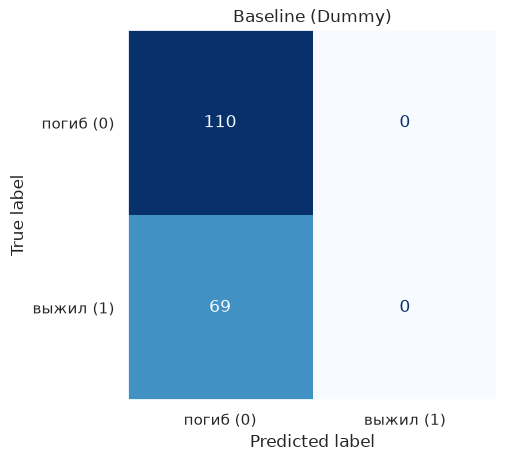

TN = 110, FP = 0, FN = 69, TP = 0


In [ ]:
from sklearn.dummy import DummyClassifier

dummy = make_pipeline(DummyClassifier(strategy="most_frequent"), scale=False)
dummy_cv = cv_f1(DummyClassifier(strategy="most_frequent"), scale=False)
dummy.fit(X_train, y_train)

y_pred_dummy = evaluate("Baseline (Dummy)", dummy, dummy_cv)
plot_cm(y_test, y_pred_dummy, "Baseline (Dummy)")

Baseline получает Accuracy 0.615, Но Precision, Recall и F1 равны 0

F1 честно показывает, что она бесполезна для поиска выживших.

## 5. Модели

### 5.1 Decision Tree

Дерево решений задаёт последовательность вопросов вида "признак <= порог?" и в каждом узле выбирает такой вопрос,
который лучше всего разделяет классы (по умолчанию — Gini = 1 − (доля выживших)² − (доля погибших)²
). В листе - самый частый класс среди
обучающих объектов, которые туда попали.

Сначала дерево без ограничений:

In [ ]:
from sklearn.tree import DecisionTreeClassifier, plot_tree

# дерево по умолчанию растёт, пока все листья не станут чистыми
dt_default = make_pipeline(DecisionTreeClassifier(random_state=RANDOM_STATE), scale=False)
dt_default.fit(X_train, y_train)

print("Train F1 = %.3f" % f1_score(y_train, dt_default.predict(X_train)))
print("CV F1    = %.3f" % cv_f1(DecisionTreeClassifier(random_state=RANDOM_STATE), scale=False))
print("Глубина дерева:", dt_default.named_steps["model"].get_depth())
print("Листьев:", dt_default.named_steps["model"].get_n_leaves())

Train F1 = 0.980


CV F1    = 0.711
Глубина дерева: 20
Листьев: 167


Явное переобучение: на train F1 = 0.98, а по кросс-валидации
F1 = 0.71. Дерево глубиной 20 и со 167 листьями - слишком много

ограничим глубину дерева (`max_depth`). Подбираем её по F1 на кросс-валидации

In [ ]:
depths = [2, 3, 4, 5, 6, 8, None]

best_score = 0
best_depth = None
for depth in depths:
    score = cv_f1(DecisionTreeClassifier(max_depth=depth, random_state=RANDOM_STATE), scale=False)
    print("max_depth = %s: CV F1 = %.3f" % (depth, score))
    # запоминаем лучший вариант
    if score > best_score:
        best_score = score
        best_depth = depth

print()
print("Лучшая глубина:", best_depth, "CV F1 = %.3f" % best_score)

max_depth = 2: CV F1 = 0.698


max_depth = 3: CV F1 = 0.763


max_depth = 4: CV F1 = 0.724


max_depth = 5: CV F1 = 0.737


max_depth = 6: CV F1 = 0.727


max_depth = 8: CV F1 = 0.726


max_depth = None: CV F1 = 0.711

Лучшая глубина: 3 CV F1 = 0.763


Decision Tree:
  Train F1 = 0.785
  Test: Accuracy = 0.832, Precision = 0.800, Recall = 0.754, F1 = 0.776


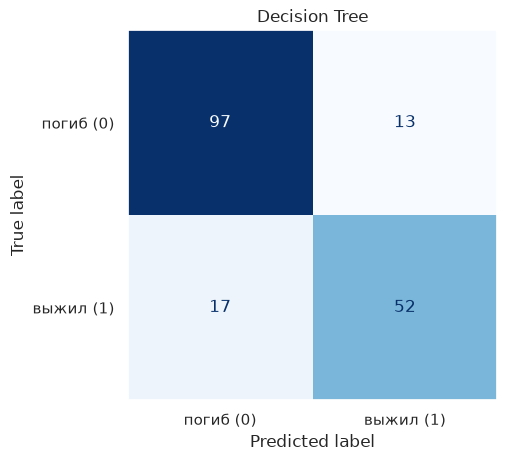

TN = 97, FP = 13, FN = 17, TP = 52


In [ ]:
dt = make_pipeline(DecisionTreeClassifier(max_depth=best_depth, random_state=RANDOM_STATE), scale=False)
dt.fit(X_train, y_train)

y_pred_dt = evaluate("Decision Tree", dt, best_score)
plot_cm(y_test, y_pred_dt, "Decision Tree")

**Сравнение train и test:** у дерева глубины 3 F1 на train, на кросс-валидации (≈0.76) и на тесте близки.

Неглубокое дерево можно нарисовать целиком и прочитать:

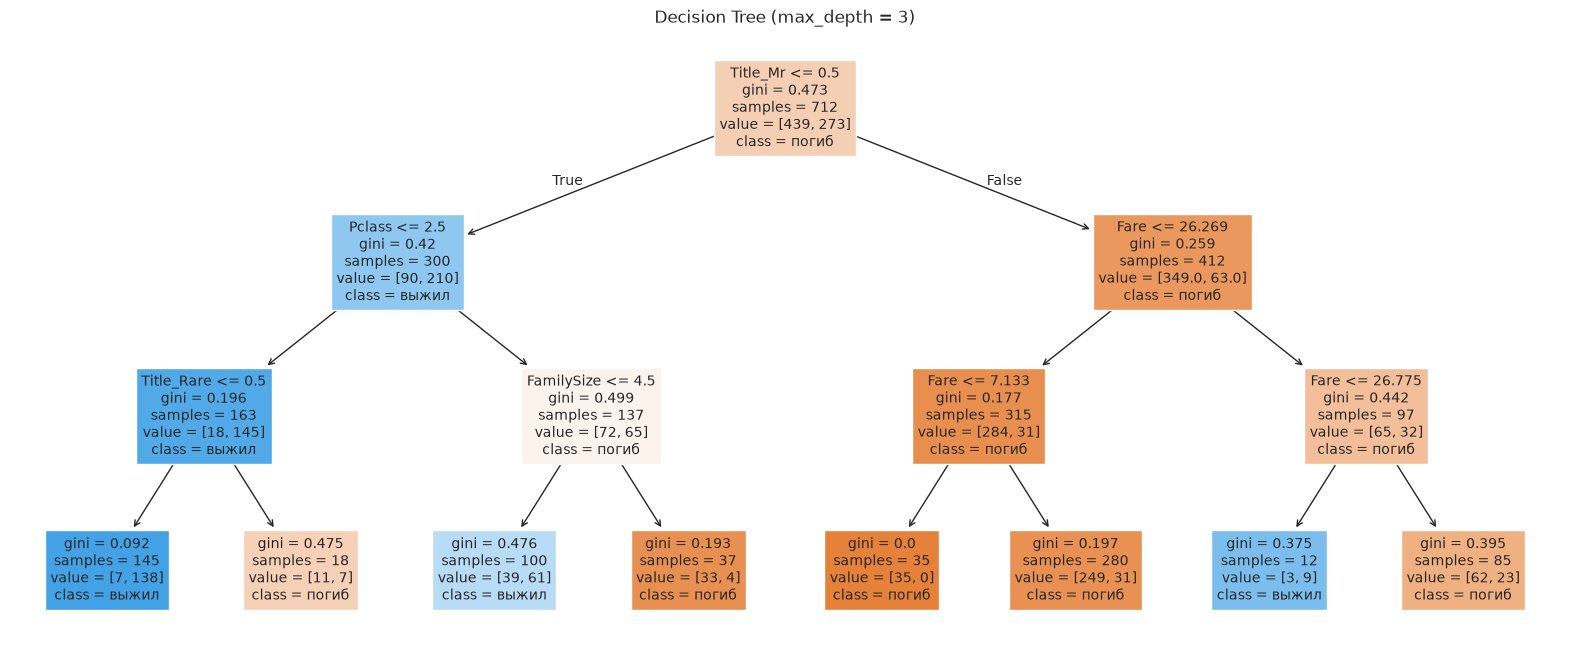

In [ ]:
# названия признаков после предобработки (убираем приставки num__ и cat__)
def get_feature_names(pipe):
    names = pipe.named_steps["prep"].get_feature_names_out()
    clean = []
    for name in names:
        clean.append(name.replace("num__", "").replace("cat__", ""))
    return clean

plt.figure(figsize=(20, 8))
plot_tree(dt.named_steps["model"], feature_names=get_feature_names(dt),
          class_names=["погиб", "выжил"], filled=True, fontsize=10)
plt.title("Decision Tree (max_depth = %d)" % best_depth)
plt.show()

- корень — `Title_Mr`. Это фактически пол + возраст в одном признаке.
- Для не Mr (женщины и мальчики) дальше важен класс: в 1-м и 2-м классе - "выжил" ,
  в 3-м классе — "выжил", только если семья не больше 4 человек.
- Для "Mr" дерево почти всегда говорит "погиб". Единственное исключение - узкое окно `Fare` от 26.27 до 26.77,
  где оно говорит "выжил".


Title_Mr        0.623
Pclass          0.154
FamilySize      0.082
Fare            0.081
Title_Rare      0.061
Sex             0.000
Age             0.000
Embarked_C      0.000
Embarked_Q      0.000
Title_Master    0.000
Embarked_S      0.000
Title_Miss      0.000
Title_Mrs       0.000
dtype: float64


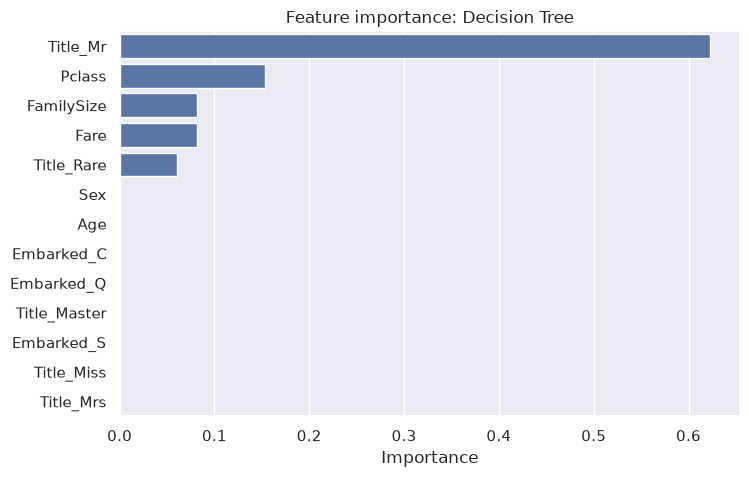

In [ ]:
# feature_importances_ — насколько суммарно уменьшилась неоднородность (Gini) при разбиениях по признаку
dt_importance = pd.Series(dt.named_steps["model"].feature_importances_,
                          index=get_feature_names(dt)).sort_values(ascending=False)
print(dt_importance.round(3))

plt.figure(figsize=(8, 5))
sns.barplot(x=dt_importance.values, y=dt_importance.index)
plt.title("Feature importance: Decision Tree")
plt.xlabel("Importance")
plt.ylabel("")
plt.show()

У дерева глубины 3 важность сосредоточена в нескольких признаках: больше всего — `Title_Mr`, потом `Pclass`
и `FamilySize`. Остальные признаки дерево вообще не использует.

### 5.2 Random Forest

Случайный лес - много деревьев, каждое обучается на своей bootstrap-выборке
и в каждом узле выбирает разбиение среди случайной части признаков . Итоговый ответ - голосование деревьев. Усреднение многих разных деревьев уменьшает
переобучение отдельного дерева.

Подбираю `max_depth` по кросс-валидации (300 деревьев).

In [ ]:
from sklearn.ensemble import RandomForestClassifier

depths = [4, 6, 8, 10, None]

best_score = 0
best_depth = None
for depth in depths:
    # n_jobs=-1 — строить деревья параллельно на всех ядрах (только быстрее)
    model = RandomForestClassifier(n_estimators=300, max_depth=depth, random_state=RANDOM_STATE, n_jobs=-1)
    score = cv_f1(model, scale=False)
    print("max_depth = %s: CV F1 = %.3f" % (depth, score))
    if score > best_score:
        best_score = score
        best_depth = depth

print()
print("Лучшая глубина:", best_depth, "CV F1 = %.3f" % best_score)

max_depth = 4: CV F1 = 0.770


max_depth = 6: CV F1 = 0.754


max_depth = 8: CV F1 = 0.749


max_depth = 10: CV F1 = 0.748


max_depth = None: CV F1 = 0.740

Лучшая глубина: 4 CV F1 = 0.770


Random Forest:
  Train F1 = 0.775
  Test: Accuracy = 0.816, Precision = 0.790, Recall = 0.710, F1 = 0.748


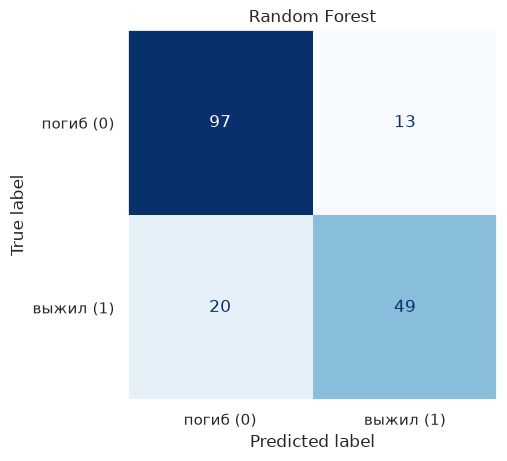

TN = 97, FP = 13, FN = 20, TP = 49


In [ ]:
# запоминаем глубину лучшего леса отдельно
rf_depth = best_depth
rf = make_pipeline(RandomForestClassifier(n_estimators=300, max_depth=rf_depth,
                                          random_state=RANDOM_STATE, n_jobs=-1), scale=False)
rf.fit(X_train, y_train)

y_pred_rf = evaluate("Random Forest", rf, best_score)
plot_cm(y_test, y_pred_rf, "Random Forest")

Лучшей оказалась небольшая глубина (4). Лес без ограничения глубины по CV хуже: глубокие деревья запоминают шум
маленькой выборки (712 человек), и даже усреднение не до конца это исправляет. F1 на train и на CV близки — переобучения нет.

Sex             0.240
Title_Mr        0.239
Pclass          0.119
Fare            0.102
Title_Mrs       0.070
Title_Miss      0.065
FamilySize      0.060
Age             0.057
Embarked_S      0.013
Embarked_C      0.012
Title_Master    0.009
Embarked_Q      0.008
Title_Rare      0.006
dtype: float64


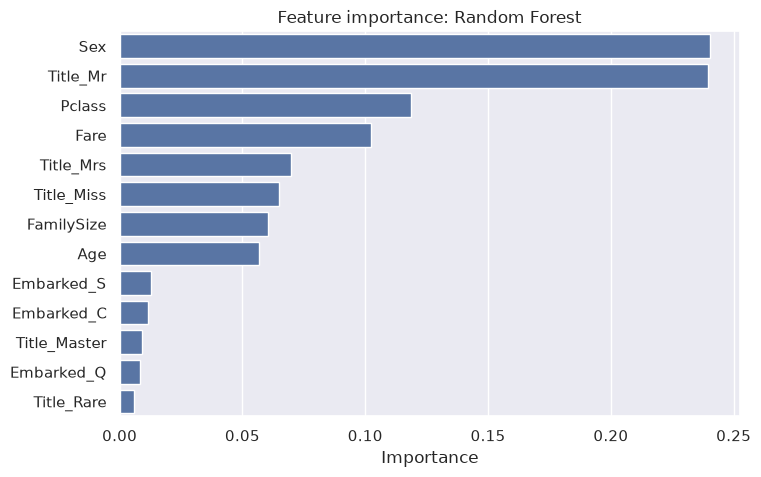

In [ ]:
rf_importance = pd.Series(rf.named_steps["model"].feature_importances_,
                          index=get_feature_names(rf)).sort_values(ascending=False)
print(rf_importance.round(3))

plt.figure(figsize=(8, 5))
sns.barplot(x=rf_importance.values, y=rf_importance.index)
plt.title("Feature importance: Random Forest")
plt.xlabel("Importance")
plt.ylabel("")
plt.show()

**Сравнение с Decision Tree:**
- В обеих моделях на первых местах признаки, связанные с полом: `Title_Mr` и `Sex`.
  Дальше — `Pclass`.
- У леса важность размазана по большему числу признаков: `Fare`, `Age`, `FamilySize`, `Title_Mrs`, `Title_Miss` тоже
  получают заметную долю.
- `Fare` у леса на 4-м месте — выше, чем `FamilySize` и `Age`, хотя по EDA цена билета в основном повторяет класс.

### 5.3 Gradient Boosting

Градиентный бустинг строит неглубокие деревья по очереди: каждое следующее дерево исправляет ошибки предыдущих
(учится на антиградиенте функции потерь - для классификации это log loss). Ответ - сумма деревьев с весом `learning_rate`,
которая потом переводится в вероятность.

Сначала параметры по умолчанию (100 деревьев, глубина 3, learning_rate = 0.1), потом несколько вариантов по CV.

In [ ]:
from sklearn.ensemble import GradientBoostingClassifier

params_list = [
    # n_estimators — количество деревьев, learning_rate — размер шага, max_depth — глубина каждого дерева
    {"n_estimators": 100, "learning_rate": 0.1,  "max_depth": 3},   # параметры по умолчанию
    {"n_estimators": 200, "learning_rate": 0.05, "max_depth": 3},
    {"n_estimators": 300, "learning_rate": 0.05, "max_depth": 3},
    {"n_estimators": 200, "learning_rate": 0.1,  "max_depth": 2},
    {"n_estimators": 100, "learning_rate": 0.1,  "max_depth": 4},
]

best_score = 0
best_params = None
for params in params_list:
    model = GradientBoostingClassifier(
        n_estimators=params["n_estimators"],
        learning_rate=params["learning_rate"],
        max_depth=params["max_depth"],
        random_state=RANDOM_STATE
    )
    score = cv_f1(model, scale=False)
    print(params, "CV F1 = %.3f" % score)
    if score > best_score:
        best_score = score
        best_params = params

print()
print("Лучшие параметры:", best_params, "CV F1 = %.3f" % best_score)

{'n_estimators': 100, 'learning_rate': 0.1, 'max_depth': 3} CV F1 = 0.757


{'n_estimators': 200, 'learning_rate': 0.05, 'max_depth': 3} CV F1 = 0.752


{'n_estimators': 300, 'learning_rate': 0.05, 'max_depth': 3} CV F1 = 0.747


{'n_estimators': 200, 'learning_rate': 0.1, 'max_depth': 2} CV F1 = 0.757


{'n_estimators': 100, 'learning_rate': 0.1, 'max_depth': 4} CV F1 = 0.762

Лучшие параметры: {'n_estimators': 100, 'learning_rate': 0.1, 'max_depth': 4} CV F1 = 0.762


Gradient Boosting:
  Train F1 = 0.921
  Test: Accuracy = 0.816, Precision = 0.790, Recall = 0.710, F1 = 0.748


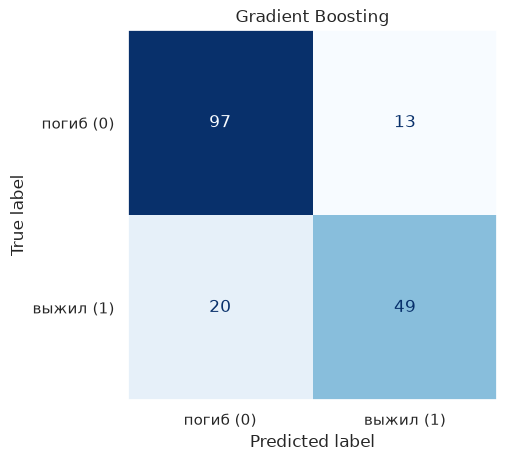

TN = 97, FP = 13, FN = 20, TP = 49


In [ ]:
gb = make_pipeline(GradientBoostingClassifier(
    n_estimators=best_params["n_estimators"],
    learning_rate=best_params["learning_rate"],
    max_depth=best_params["max_depth"],
    random_state=RANDOM_STATE
), scale=False)
gb.fit(X_train, y_train)

y_pred_gb = evaluate("Gradient Boosting", gb, best_score)
plot_cm(y_test, y_pred_gb, "Gradient Boosting")

Разница между вариантами параметров маленькая (CV F1 от 0.75 до 0.76), то есть бустинг на этих данных
не очень чувствителен к настройке. Лучшим оказался вариант с более глубокими деревьями (глубина 4).

Title_Mr        0.381
Fare            0.216
Age             0.133
Pclass          0.109
FamilySize      0.067
Title_Rare      0.036
Sex             0.028
Embarked_S      0.015
Embarked_Q      0.004
Title_Miss      0.004
Title_Master    0.003
Title_Mrs       0.002
Embarked_C      0.002
dtype: float64


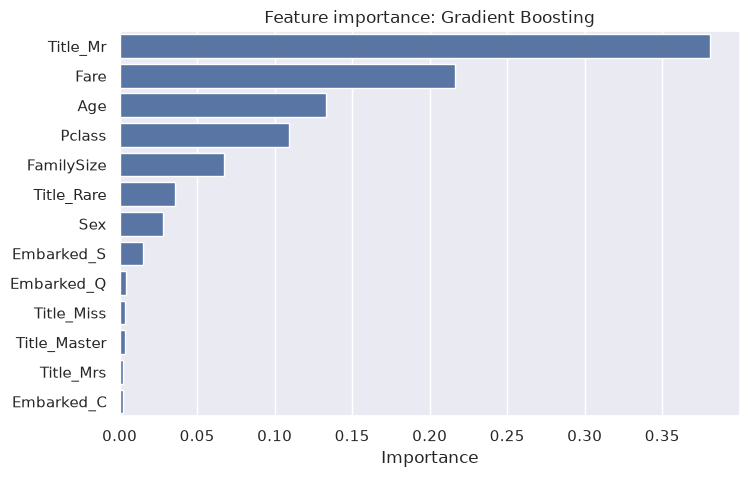

In [ ]:
gb_importance = pd.Series(gb.named_steps["model"].feature_importances_,
                          index=get_feature_names(gb)).sort_values(ascending=False)
print(gb_importance.round(3))

plt.figure(figsize=(8, 5))
sns.barplot(x=gb_importance.values, y=gb_importance.index)
plt.title("Feature importance: Gradient Boosting")
plt.xlabel("Importance")
plt.ylabel("")
plt.show()

Сравнение с Random Forest:
- У бустинга `Title_Mr` забирает гораздо большую долю важности, а `Sex` почти не используется.
- У бустинга выше важность `Fare` и `Age`: после того как первые деревья учли пол и класс, следующие деревья
  "дорабатывают" ошибки с помощью признаков с большим количеством значений, на которых легко найти мелкие закономерности
  (и шум тоже — отсюда высокий F1 на train).
- В целом обе модели согласны: главное - пол/обращение и класс, дальше — стоимость билета, возраст и размер семьи.

### 5.4 Support Vector Machine

SVM ищет границу между классами с максимальным зазором чтобы ближайшие к границе объекты
были как можно дальше от неё. С ядром RBF (по умолчанию) граница может быть нелинейной. большой `C` - модель старается не ошибаться на train,
маленький - допускает ошибки ради более широкого и простого зазора.

**Нужно ли масштабирование?** Да. Зазор и ядро RBF считаются через расстояния между объектами. Без масштабирования
расстояние почти полностью определяется `Fare` (значения до 512) и `Age` (до 80), а пол (0/1) и класс (1–3) почти не влияют.
Проверю это по кросс-валидации:

In [ ]:
from sklearn.svm import SVC

print("SVM без масштабирования: CV F1 = %.3f" % cv_f1(SVC(random_state=RANDOM_STATE), scale=False))
print("SVM с масштабированием:  CV F1 = %.3f" % cv_f1(SVC(random_state=RANDOM_STATE), scale=True))

SVM без масштабирования: CV F1 = 0.443
SVM с масштабированием:  CV F1 = 0.752


Без масштабирования SVM почти бесполезен (F1 = 0.44), с масштабированием - около 0.75.


In [ ]:
C_values = [0.1, 0.5, 1, 3, 10]

best_score = 0
best_C = None
for C in C_values:
    score = cv_f1(SVC(C=C, random_state=RANDOM_STATE), scale=True)
    print("C = %s: CV F1 = %.3f" % (C, score))
    if score > best_score:
        best_score = score
        best_C = C

print()
print("Лучшее C:", best_C, "CV F1 = %.3f" % best_score)

C = 0.1: CV F1 = 0.734


C = 0.5: CV F1 = 0.762
C = 1: CV F1 = 0.752


C = 3: CV F1 = 0.745


C = 10: CV F1 = 0.739

Лучшее C: 0.5 CV F1 = 0.762


SVM:
  Train F1 = 0.773
  Test: Accuracy = 0.838, Precision = 0.833, Recall = 0.725, F1 = 0.775


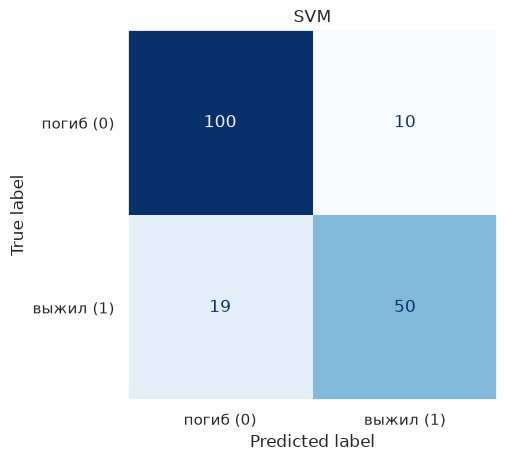

TN = 100, FP = 10, FN = 19, TP = 50


In [ ]:
svm = make_pipeline(SVC(C=best_C, random_state=RANDOM_STATE), scale=True)
svm.fit(X_train, y_train)

y_pred_svm = evaluate("SVM", svm, best_score)
plot_cm(y_test, y_pred_svm, "SVM")

Лучшим оказалось небольшое `C = 0.5`. F1 на train и на CV почти равны — переобучения нет.
У SVM нет встроенной feature importance , её можно оценить только через
permutation importance.

### 5.5 K-Nearest Neighbors

KNN запоминает train, а для нового пассажира находит `k` самых похожих
пассажиров из train и выбирает класс голосованием.

Если не масштабировать признаки,
у двух пассажиров с разницей в цене билета 50 и одинаковым полом расстояние будет ≈50, а у двух пассажиров
с одинаковой ценой, но разным полом — всего 1. То есть KNN будет считать соседями людей с похожей ценой билета
и почти не обращать внимания на пол — самый важный признак. После `StandardScaler` все признаки вносят сопоставимый вклад.

In [ ]:
from sklearn.neighbors import KNeighborsClassifier

print("KNN (k=5) без масштабирования: CV F1 = %.3f" % cv_f1(KNeighborsClassifier(n_neighbors=5), scale=False))
print("KNN (k=5) с масштабированием:  CV F1 = %.3f" % cv_f1(KNeighborsClassifier(n_neighbors=5), scale=True))

KNN (k=5) без масштабирования: CV F1 = 0.604


KNN (k=5) с масштабированием:  CV F1 = 0.743


Без масштабирования F1 ≈ 0.60, с масштабированием ≈ 0.74
Подбираю число соседей `k`: маленькое `k` - модель чувствительна к шуму,
большое - граница сглаживается, но мелкие закономерности теряются.

In [ ]:
k_values = [3, 5, 7, 9, 11, 15, 21]

best_score = 0
best_k = None
for k in k_values:
    score = cv_f1(KNeighborsClassifier(n_neighbors=k), scale=True)
    print("k = %d: CV F1 = %.3f" % (k, score))
    if score > best_score:
        best_score = score
        best_k = k

print()
print("Лучшее k:", best_k, "CV F1 = %.3f" % best_score)

k = 3: CV F1 = 0.751
k = 5: CV F1 = 0.743


k = 7: CV F1 = 0.739


k = 9: CV F1 = 0.741
k = 11: CV F1 = 0.740
k = 15: CV F1 = 0.747


k = 21: CV F1 = 0.734

Лучшее k: 3 CV F1 = 0.751


KNN:
  Train F1 = 0.835
  Test: Accuracy = 0.827, Precision = 0.806, Recall = 0.725, F1 = 0.763


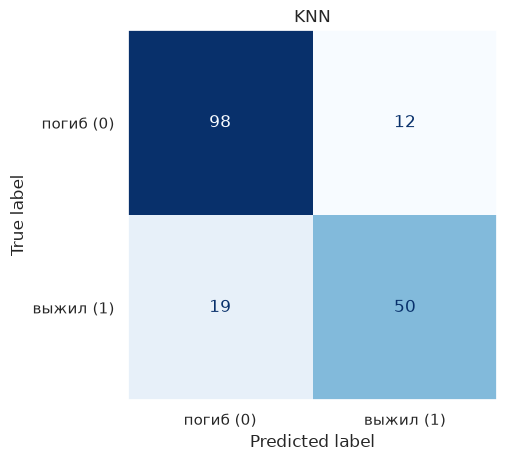

TN = 98, FP = 12, FN = 19, TP = 50


In [ ]:
knn = make_pipeline(KNeighborsClassifier(n_neighbors=best_k), scale=True)
knn.fit(X_train, y_train)

y_pred_knn = evaluate("KNN", knn, best_score)
plot_cm(y_test, y_pred_knn, "KNN")

Разница в CV между разными `k` маленькая (0.73–0.75), лучшим оказалось `k = 3`. У KNN с маленьким `k` F1 на train
(~0.84) заметно выше, чем на CV (~0.75): при `k = 3` каждый объект train сам является одним из своих трёх соседей,
поэтому на train модель частично "подсматривает" ответ. У KNN тоже нет встроенной feature importance.

## 6. Честное сравнение моделей

Все модели обучались на одном и том же train, параметры выбирались по одной и той же кросс-валидации (5 фолдов,
`random_state=42`), а оценивались на одном и том же test.

In [ ]:
results_table = pd.DataFrame(results, columns=["Модель", "Accuracy", "Precision", "Recall", "F1",
                                                "F1 (train)", "F1 (CV)"])
results_table["F1 > 0.70"] = results_table["F1"] > 0.70
results_table.round(3)

,Модель,Accuracy,Precision,Recall,F1,F1 (train),F1 (CV),F1 > 0.70
0,Baseline (Dummy),0.615,0.000,0.000,0.000,0.000,0.000,False
1,Decision Tree,0.832,0.800,0.754,0.776,0.785,0.763,True
2,Random Forest,0.816,0.790,0.710,0.748,0.775,0.770,True
3,Gradient Boosting,0.816,0.790,0.710,0.748,0.921,0.762,True
4,SVM,0.838,0.833,0.725,0.775,0.773,0.762,True
5,KNN,0.827,0.806,0.725,0.763,0.835,0.751,True


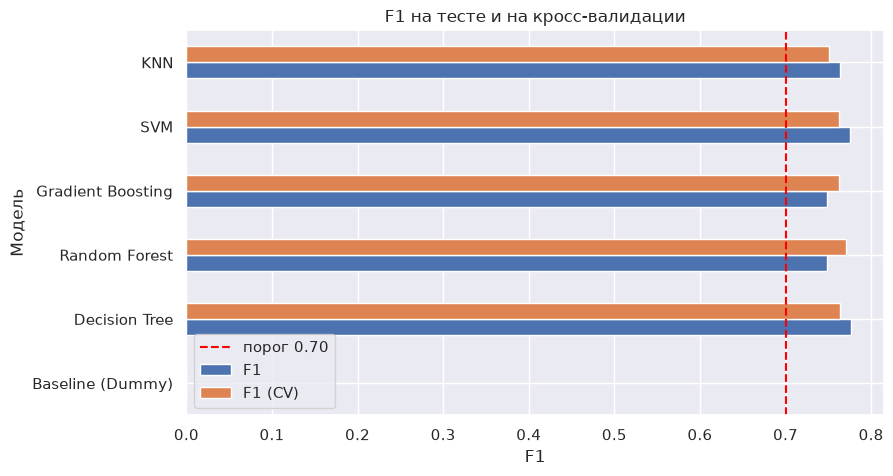

In [ ]:
plot_df = results_table.set_index("Модель")[["F1", "F1 (CV)"]]
plot_df.plot(kind="barh", figsize=(9, 5))
plt.axvline(0.70, color="red", linestyle="--", label="порог 0.70")
plt.legend()
plt.title("F1 на тесте и на кросс-валидации")
plt.xlabel("F1")
plt.show()

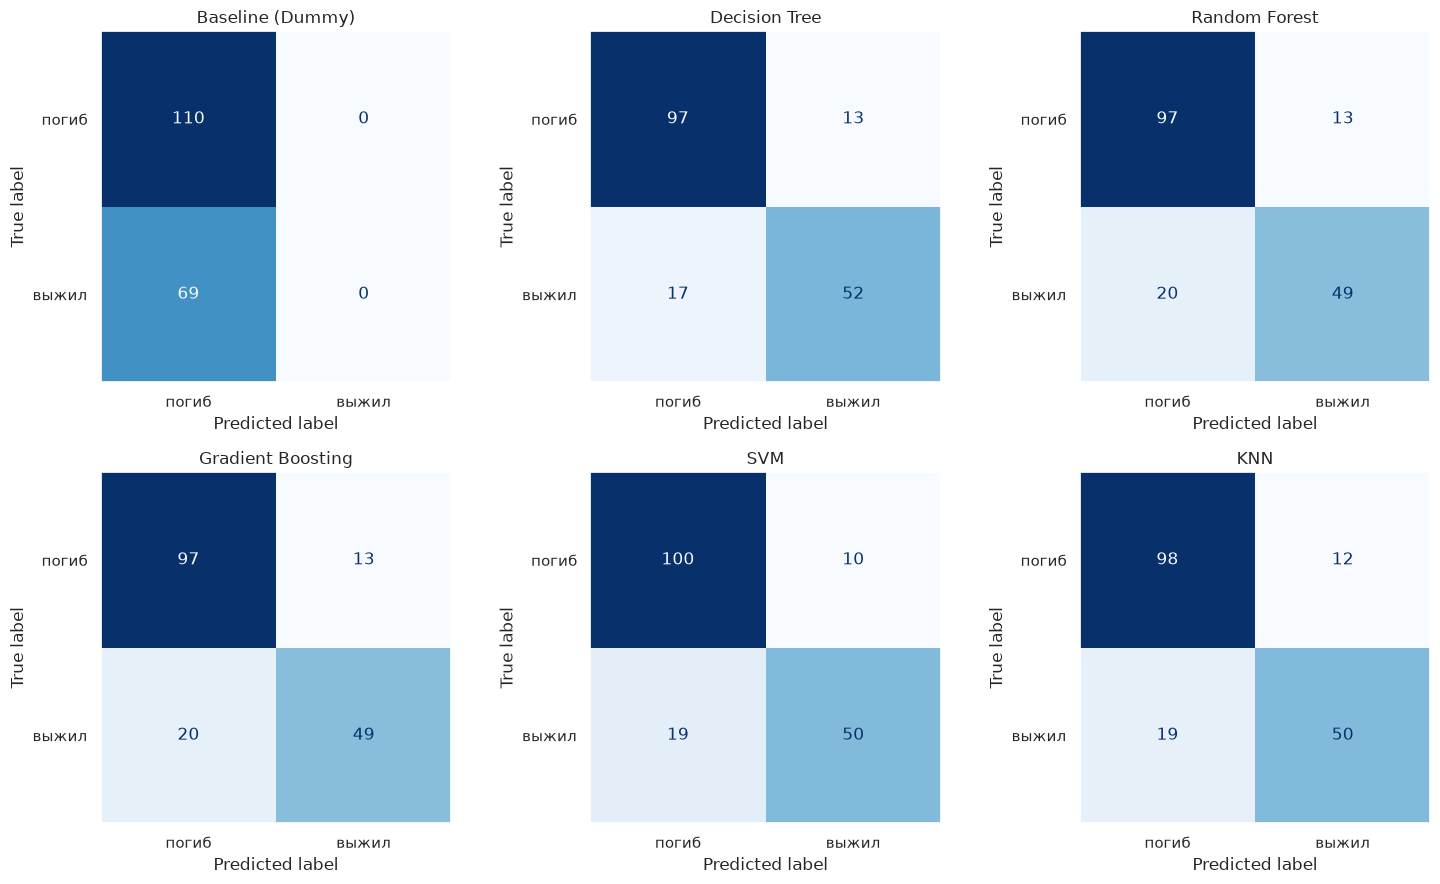

In [ ]:
fig, axs = plt.subplots(2, 3, figsize=(15, 9))
axs = axs.flatten()
for i, name in enumerate(test_predictions):
    ConfusionMatrixDisplay.from_predictions(
        y_test, test_predictions[name], display_labels=["погиб", "выжил"],
        cmap="Blues", colorbar=False, ax=axs[i]
    )
    axs[i].set_title(name)
    axs[i].grid(False)
plt.tight_layout()
plt.show()

**Анализ результатов:**

1. Все 5 моделей превзошли baseline и прошли порог F1 > 0.70.
2. **Разница между моделями очень маленькая.**. Тест из 179 человек слишком маленький, чтобы уверенно сказать, какая модель лучше.
3. **Переобучение:** у Gradient Boosting и KNN (k=3) F1 на train заметно выше, чем на CV — они сильнее подстраиваются
   под обучающую выборку. У Decision Tree (глубина 3), Random Forest (глубина 4) и SVM (C=0.5) train и CV близки.
5. SVM и KNN работают на уровне деревьев только после масштабирования: без него их F1 был 0.44 и 0.60.
6. Precision у всех моделей выше Recall. Модели чаще ошибаются в сторону "погиб": FN больше,
   чем FP. 

Лучшую
модель выбираю по F1 на кросс-валидации: это Random Forest (глубина 4). На тесте у него F1 чуть ниже, чем у дерева
и SVM, но эта разница — на уровне 1–2 пассажиров и не говорит о реальном превосходстве. Лес к тому же устойчивее
одного дерева (не зависит так сильно от конкретных объектов в выборке).

In [ ]:
# лучшая модель — с максимальным F1 на кросс-валидации (не по тесту!)
best_row = results_table.loc[results_table["F1 (CV)"].idxmax()]
print("Лучшая модель по CV:", best_row["Модель"])
print("F1 (CV) = %.3f, F1 (test) = %.3f" % (best_row["F1 (CV)"], best_row["F1"]))

Лучшая модель по CV: Random Forest
F1 (CV) = 0.770, F1 (test) = 0.748


## 7. Feature importance

### 7.1 Встроенная важность у деревьев

Сравню важность признаков у трёх моделей, которые её позволяют получить. 

In [ ]:
compare = pd.DataFrame({
    "Decision Tree": dt_importance,
    "Random Forest": rf_importance,
    "Gradient Boosting": gb_importance
})
compare = compare.sort_values("Random Forest", ascending=False)
compare.round(3)

,Decision Tree,Random Forest,Gradient Boosting
Sex,0.000,0.240,0.028
Title_Mr,0.623,0.239,0.381
Pclass,0.154,0.119,0.109
Fare,0.081,0.102,0.216
Title_Mrs,0.000,0.070,0.002
Title_Miss,0.000,0.065,0.004
FamilySize,0.082,0.060,0.067
Age,0.000,0.057,0.133
Embarked_S,0.000,0.013,0.015
Embarked_C,0.000,0.012,0.002


In [ ]:
# ранги: в каждом столбце самое большое значение получает 1
# method="min" — у одинаковых значений (например, нескольких нулей у дерева) одинаковый ранг
compare.rank(ascending=False, method="min").astype(int)

,Decision Tree,Random Forest,Gradient Boosting
Sex,6,1,7
Title_Mr,1,2,1
Pclass,2,3,4
Fare,4,4,2
Title_Mrs,6,5,12
Title_Miss,6,6,10
FamilySize,3,7,5
Age,6,8,3
Embarked_S,6,9,8
Embarked_C,6,10,13


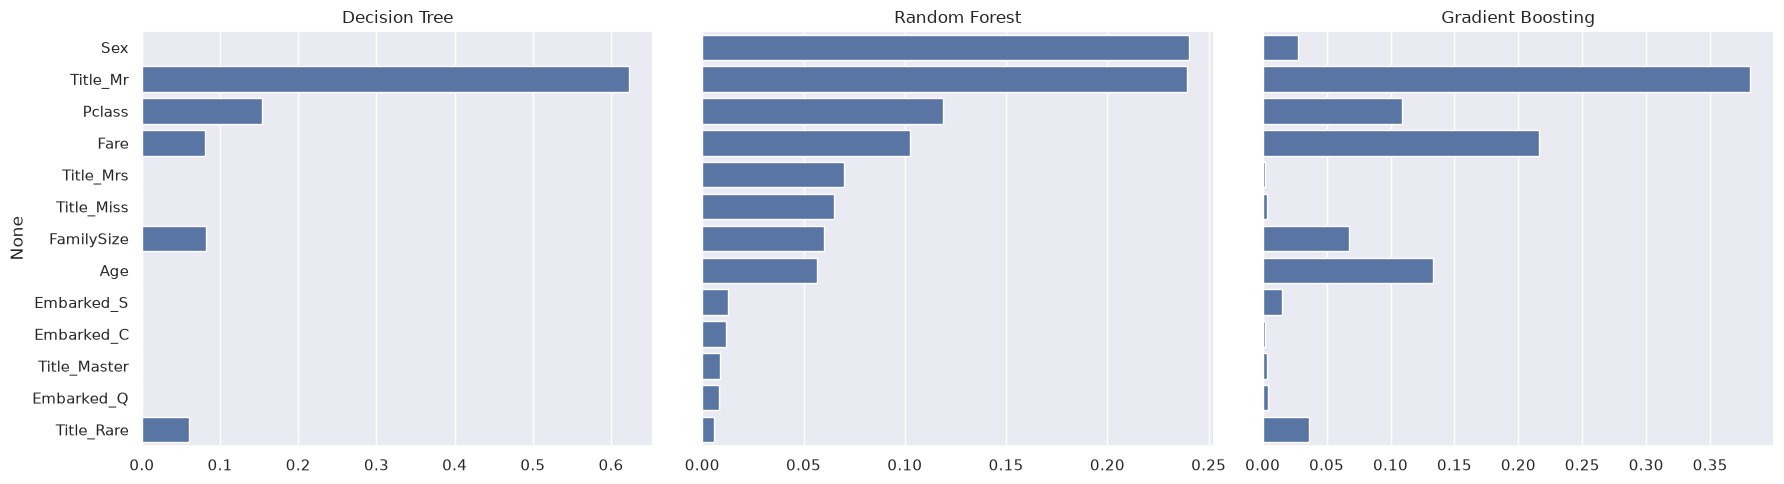

In [ ]:
# три графика рядом с общей осью Y (признаки в одном порядке)
fig, axs = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
for i, col in enumerate(compare.columns):
    sns.barplot(x=compare[col].values, y=compare.index, ax=axs[i])
    axs[i].set_title(col)
plt.tight_layout()
plt.show()

### 7.2 Permutation importance

Встроенная важность деревьев имеет недостатки: она завышает признаки с большим числом разных значений (`Fare`, `Age`)
и делит важность между похожими признаками (`Sex` и `Title_Mr`). К тому же у SVM и KNN её вообще нет.

**Permutation importance** работает для любой модели: берём один признак, случайно перемешиваем его значения
между пассажирами (связь признака с ответом разрушается) и смотрим, насколько упал F1. Чем больше падение,
тем важнее признак. Важно, что перемешивается исходный столбец до One-Hot, поэтому, например, `Title`
оценивается целиком.

Считаю её на тесте: здесь тест не используется для выбора модели, а только для объяснения уже выбранных моделей.

In [ ]:
from sklearn.inspection import permutation_importance

models = {"Decision Tree": dt, "Random Forest": rf, "Gradient Boosting": gb, "SVM": svm, "KNN": knn}

perm_table = {}
for name in models:
    # n_repeats=20 — перемешиваем каждый признак 20 раз и берём среднее падение F1
    perm = permutation_importance(models[name], X_test, y_test, scoring="f1",
                                  n_repeats=20, random_state=RANDOM_STATE)
    perm_table[name] = pd.Series(perm.importances_mean, index=X_test.columns)

perm_table = pd.DataFrame(perm_table).sort_values("Random Forest", ascending=False)
perm_table.round(3)

,Decision Tree,Random Forest,Gradient Boosting,SVM,KNN
Title,0.368,0.190,0.256,0.065,0.054
Sex,0.000,0.077,0.038,0.281,0.220
FamilySize,0.047,0.050,0.016,0.048,0.044
Pclass,0.034,0.017,0.089,0.044,0.121
Embarked,0.000,0.011,0.013,-0.006,0.029
Age,0.000,0.009,0.039,0.026,0.070
Fare,0.015,-0.004,0.049,0.013,0.027


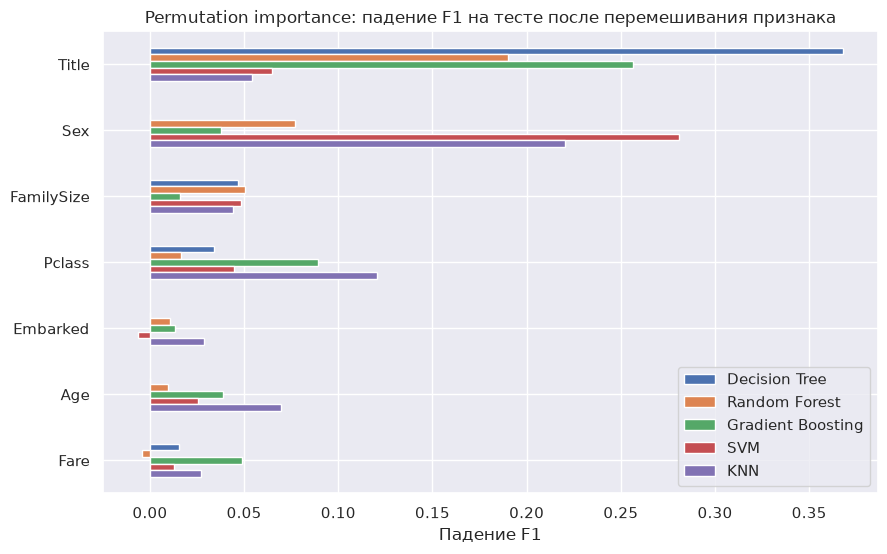

In [ ]:
perm_table.plot(kind="barh", figsize=(10, 6))
plt.title("Permutation importance: падение F1 на тесте после перемешивания признака")
plt.xlabel("Падение F1")
plt.gca().invert_yaxis()
plt.show()

**Выводы по важности признаков:**

1. Самый важный признак - пол (в виде `Sex` или `Title`). Это видно и во встроенной важности всех трёх деревьев,
   и в permutation importance всех пяти моделей
   Дальше идут класс (`Pclass`) и размер семьи (`FamilySize`) - падение F1 около 0.02–0.12.
2. `Sex` и `Title` дублируют друг друга. У деревьев в permutation importance главный - `Title`, а `Sex` почти не важен.
   У SVM и KNN наоборот: главный - `Sex`, а `Title` важен слабо. Если перемешать один из них, модель всё равно знает пол
   из другого (Mr / Mrs / Miss).
3. `Fare` и `Age` во встроенной важности леса и бустинга стоят высоко, но в permutation importance их вклад намного меньше.
   Это подтверждает, что встроенная важность завышает признаки с большим количеством разных значений.
4. `FamilySize` у всех моделей даёт падение F1 около 0.02–0.05
5. `Embarked` почти ни на что не влияет

Нельзя сказать, что важный признак - причина выживания. Feature importance показывает, на что опирается
модель при предсказании, а не что *вызвало* выживание:


## 8. Анализ ошибок лучшей модели

Лучшая модель по кросс-валидации - Random Forest. 

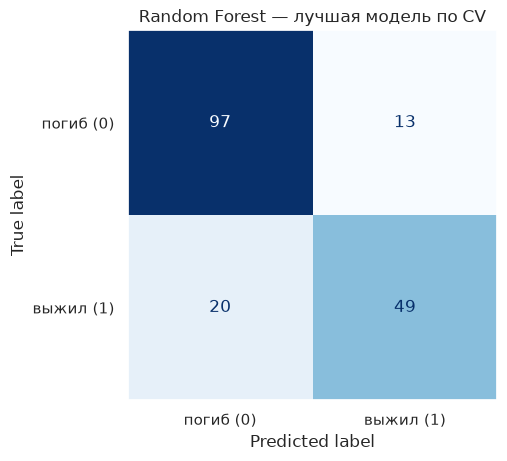

TN = 97, FP = 13, FN = 20, TP = 49


In [ ]:
plot_cm(y_test, y_pred_rf, "Random Forest — лучшая модель по CV")

In [ ]:
# таблица для анализа: признаки тестовых пассажиров + имя + правда + предсказание
errors_df = X_test.copy()
errors_df["Name"] = data.loc[X_test.index, "Name"]
errors_df["Survived"] = y_test
errors_df["pred"] = y_pred_rf

# тип ответа для каждого пассажира
def answer_type(row):
    if row["Survived"] == 1 and row["pred"] == 1:
        return "TP"
    if row["Survived"] == 0 and row["pred"] == 0:
        return "TN"
    if row["Survived"] == 0 and row["pred"] == 1:
        return "FP"
    return "FN"

# apply с axis=1 — применяем функцию к каждой строке
errors_df["type"] = errors_df.apply(answer_type, axis=1)
# для читаемости возвращаем пол словами
errors_df["Sex_text"] = errors_df["Sex"].map({0: "male", 1: "female"})

print(errors_df["type"].value_counts())

type
TN    97
TP    49
FN    20
FP    13
Name: count, dtype: int64


FN (пропущенных выживших) больше, чем FP (ложных "выжил"). Модель скорее недооценивает шансы
пассажиров

In [ ]:
# ошибки по группам "пол + класс": сколько людей, доля ошибок, сколько FP и FN
groups = []
for (sex, pclass), part in errors_df.groupby(["Sex_text", "Pclass"]):
    groups.append([sex, pclass, len(part),
                   round(part["Survived"].mean(), 2),          # реальная доля выживших в группе
                   round(part["pred"].mean(), 2),              # доля "выжил" в предсказаниях
                   round((part["type"].isin(["FP", "FN"])).mean(), 2),   # доля ошибок
                   (part["type"] == "FP").sum(),
                   (part["type"] == "FN").sum()])

groups = pd.DataFrame(groups, columns=["пол", "класс", "человек", "выжило (факт)", "выжило (прогноз)",
                                       "доля ошибок", "FP", "FN"])
groups

,пол,класс,человек,выжило (факт),выжило (прогноз),доля ошибок,FP,FN
0,female,1,15,0.93,1.00,0.07,1,0
1,female,2,18,0.94,1.00,0.06,1,0
2,female,3,28,0.50,0.82,0.32,9,0
3,male,1,30,0.37,0.10,0.40,2,10
4,male,2,16,0.19,0.06,0.12,0,2
5,male,3,72,0.14,0.03,0.11,0,8


In [ ]:
# то же самое по обращению (Title)
by_title = errors_df.groupby("Title").agg(
    человек=("type", "size"),
    выжило_факт=("Survived", "mean"),
    выжило_прогноз=("pred", "mean"),
)
# доля ошибок в каждой группе
by_title["доля ошибок"] = errors_df.groupby("Title")["type"].apply(lambda t: t.isin(["FP", "FN"]).mean())
by_title.round(2)

,человек,выжило_факт,выжило_прогноз,доля ошибок
Title,,,,
Master,9,0.67,0.44,0.22
Miss,41,0.68,0.88,0.20
Mr,105,0.17,0.00,0.17
Mrs,19,0.84,1.00,0.16
Rare,5,0.20,0.60,0.40


**Для каких групп модель ошибается заметнее всего:**
- Мужчины из 1-го класса - 40% ошибок, все они FN. 
- Женщины из 3-го класса - 32% ошибок, и все они FP. 

**Все 20 FN - мужчины и мальчики, а 11 из 13 FP — женщины и девочки.** Модель, по сути, выучила правило эвакуации
(женщины выживают, мужчины нет) и ошибается там, где само правило не давало однозначного ответа.


In [53]:
# несколько ошибочных примеров: показываем исходные данные пассажира
show_cols = ["Name", "Sex_text", "Pclass", "Age", "Fare", "FamilySize", "Embarked", "Title", "Survived", "pred", "type"]

print("Ложные 'выжил' (FP):")
errors_df[errors_df["type"] == "FP"][show_cols]

Ложные 'выжил' (FP):


,Name,Sex_text,Pclass,Age,Fare,FamilySize,Embarked,Title,Survived,pred,type
745,"Crosby, Capt. Edward Gifford",male,1,70.0,71.0000,3,S,Rare,0,1,FP
297,"Allison, Miss. Helen Loraine",female,1,2.0,151.5500,4,S,Miss,0,1,FP
40,"Ahlin, Mrs. Johan (Johanna Persdotter Larsson)",female,3,40.0,9.4750,2,S,Mrs,0,1,FP
564,"Meanwell, Miss. (Marion Ogden)",female,3,NaN,8.0500,1,S,Miss,0,1,FP
502,"O'Sullivan, Miss. Bridget Mary",female,3,NaN,7.6292,1,Q,Miss,0,1,FP
578,"Caram, Mrs. Joseph (Maria Elias)",female,3,NaN,14.4583,2,C,Mrs,0,1,FP
38,"Vander Planke, Miss. Augusta Maria",female,3,18.0,18.0000,3,S,Miss,0,1,FP
593,"Bourke, Miss. Mary",female,3,NaN,7.7500,3,Q,Miss,0,1,FP
501,"Canavan, Miss. Mary",female,3,21.0,7.7500,1,Q,Miss,0,1,FP
245,"Minahan, Dr. William Edward",male,1,44.0,90.0000,3,Q,Rare,0,1,FP


In [54]:
print("Пропущенные выжившие (FN):")
errors_df[errors_df["type"] == "FN"][show_cols].head(12)

Пропущенные выжившие (FN):


,Name,Sex_text,Pclass,Age,Fare,FamilySize,Embarked,Title,Survived,pred,type
553,"Leeni, Mr. Fahim (""Philip Zenni"")",male,3,22.0,7.2250,1,C,Mr,1,0,FN
712,"Taylor, Mr. Elmer Zebley",male,1,48.0,52.0000,2,S,Mr,1,0,FN
455,"Jalsevac, Mr. Ivan",male,3,29.0,7.8958,1,C,Mr,1,0,FN
489,"Coutts, Master. Eden Leslie ""Neville""",male,3,9.0,15.9000,3,S,Master,1,0,FN
165,"Goldsmith, Master. Frank John William ""Frankie""",male,3,9.0,20.5250,3,S,Master,1,0,FN
17,"Williams, Mr. Charles Eugene",male,2,NaN,13.0000,1,S,Mr,1,0,FN
679,"Cardeza, Mr. Thomas Drake Martinez",male,1,36.0,512.3292,2,C,Mr,1,0,FN
701,"Silverthorne, Mr. Spencer Victor",male,1,35.0,26.2875,1,S,Mr,1,0,FN
447,"Seward, Mr. Frederic Kimber",male,1,34.0,26.5500,1,S,Mr,1,0,FN
690,"Dick, Mr. Albert Adrian",male,1,31.0,57.0000,2,S,Mr,1,0,FN


**Разбор ошибок**:

- FP - в основном женщины из 3-го класса (9 из 13): 
  Почти все они ехали одни или с маленькой семьёй и с дешёвым билетом (7–25), у многих не указан возраст (его заполнили
  медианой).
- Allison, Miss. Helen Loraine (FP) - 2-летняя девочка из 1-го класса. Погибла(?)
- Crosby, Capt. Edward Gifford (FP) - 70-летний мужчина из 1-го класса с редким обращением `Capt`.
- FN - все мужчины. Во-первых, мужчины 1-го класса: Cardeza,
  Taylor, Silverthorne, Seward, Dick, Woolner.
- Мальчики из 3-го класса - Coutts и Goldsmith, обоим по 9 лет, семьи по 3 человека.

Общий вывод: большая часть ошибок - это пассажиры, чей исход противоречит основной закономерности своей группы.

### 8.1 Не связано ли качество с признаками, которые идентифицируют пассажира?

Я заранее убрал `PassengerId`, `Name`, `Ticket` и `Cabin`. Проверю, что было бы, если бы их оставили, -
и убедимся, что наша модель их не использует.

добавляем каждый подозрительный признак к нашим признакам и смотрю на F1 случайного леса
на train и на кросс-валидации. Если признак позволяет запоминать пассажиров, F1 на train вырастет почти до 1,
а на CV не вырастет (или упадёт).

In [55]:
# для эксперимента беру лес без ограничения глубины — он лучше всего умеет "запоминать" отдельных пассажиров
def rf_model():
    return RandomForestClassifier(n_estimators=300, max_depth=None, random_state=RANDOM_STATE, n_jobs=-1)

experiments = [
    ("наши признаки", num_features, cat_features),
    ("+ PassengerId", num_features + ["PassengerId"], cat_features),
    ("+ Ticket (One-Hot)", num_features, cat_features + ["Ticket"]),
    ("+ Name (One-Hot)", num_features, cat_features + ["Name"]),
]

exp_results = []
for title, num_cols, cat_cols in experiments:
    # берём те же строки train, что и раньше, но с дополнительными столбцами
    X_tr = data.loc[X_train.index, num_cols + cat_cols]
    pipe = make_pipeline(rf_model(), scale=False, num_cols=num_cols, cat_cols=cat_cols)
    scores = cross_val_score(pipe, X_tr, y_train, cv=cv, scoring="f1")
    pipe.fit(X_tr, y_train)
    train_score = f1_score(y_train, pipe.predict(X_tr))
    # std — насколько F1 отличается между 5 фолдами (показывает "шум" оценки)
    exp_results.append([title, round(train_score, 3), round(scores.mean(), 3), round(scores.std(), 3)])

pd.DataFrame(exp_results, columns=["признаки", "F1 train", "F1 CV", "разброс CV (std)"])

,признаки,F1 train,F1 CV,разброс CV (std)
0,наши признаки,0.98,0.740,0.020
1,+ PassengerId,1.00,0.728,0.025
2,+ Ticket (One-Hot),1.00,0.763,0.033
3,+ Name (One-Hot),1.00,0.754,0.036


In [56]:
# какую важность лес даёт PassengerId, если его добавить
X_tr = data.loc[X_train.index, num_features + ["PassengerId"] + cat_features]
pipe = make_pipeline(rf_model(), scale=False, num_cols=num_features + ["PassengerId"], cat_cols=cat_features)
pipe.fit(X_tr, y_train)
id_importance = pd.Series(pipe.named_steps["model"].feature_importances_,
                          index=get_feature_names(pipe)).sort_values(ascending=False)
id_importance.round(3).head(6)

Fare           0.180
PassengerId    0.175
Age            0.148
Title_Mr       0.121
Sex            0.118
Pclass         0.078
dtype: float64

- **`PassengerId`** — просто номер строки, никакого смысла в нём нет. Но лес ставит его на 2-е место по важности
- **`Ticket` и `Name`** после One-Hot превращаются в сотни столбцов, по одному на билет/человека. F1 на train — 1.00:
  модель может запомнить каждого.

### 8.2 Признак Cabin

Номер каюты известен только у 23% пассажиров. Проверим, не связан ли сам факт того, что каюта записана, с выживанием
сильнее, чем это объясняется классом.

In [57]:
# 1 — каюта записана, 0 — нет
has_cabin = data["Cabin"].notnull().astype(int)

# доля выживших в каждом классе отдельно для пассажиров с записанной каютой и без
pd.crosstab(data["Pclass"], has_cabin, values=data["Survived"], aggfunc="mean").round(3)

Cabin,0,1
Pclass,,
1,0.475,0.665
2,0.440,0.812
3,0.236,0.500


In [58]:
# как изменится качество леса, если добавить признак "каюта записана"
data["HasCabin"] = has_cabin
X_tr = data.loc[X_train.index, num_features + ["HasCabin"] + cat_features]
pipe = make_pipeline(RandomForestClassifier(n_estimators=300, max_depth=rf_depth, random_state=RANDOM_STATE, n_jobs=-1),
                     scale=False, num_cols=num_features + ["HasCabin"], cat_cols=cat_features)
print("Random Forest без HasCabin: CV F1 = %.3f" % results_table.loc[results_table["Модель"] == "Random Forest", "F1 (CV)"].values[0])
print("Random Forest с HasCabin:   CV F1 = %.3f" % cross_val_score(pipe, X_tr, y_train, cv=cv, scoring="f1").mean())

Random Forest без HasCabin: CV F1 = 0.770


Random Forest с HasCabin:   CV F1 = 0.764


Даже **внутри одного класса** пассажиры с записанной каютой выживали намного чаще (например, в 1-м классе
66% против 48%, во 2-м — 81% против 44%). Класс это не объясняет.


## 9. Выводы

1. **Данные.** 891 пассажир, выжило 38% — классы несбалансированы, поэтому основная метрика — F1, а не Accuracy.
   Главные факторы по EDA — пол (74% женщин против 19% мужчин), класс (63% в 1-м против 24% в 3-м), возраст (дети)
   и размер семьи. Связи часто нелинейные и проявляются в сочетаниях (женщины 3-го класса — 50%).
2. **Подготовка.** Удалены признаки-идентификаторы (`PassengerId`, `Name`, `Ticket`) и подозрительный `Cabin`.
   Добавлены `Title` (обращение из имени) и `FamilySize`. Пропуски `Age` — медианой, `Embarked` — самым частым значением,
   категории — One-Hot. Всё, что "учится" на данных, обучается только на train внутри Pipeline.
   Разбиение 80/20 со стратификацией, `random_state=42`.
3. **Baseline** (всегда "погиб"): Accuracy 0.615, но F1 = 0 — отличный пример того, почему Accuracy обманчива.
4. **Модели.** Все пять моделей прошли порог F1 > 0.70, их F1 на тесте — от ~0.75 до ~0.78. Разница между ними на уровне
   1–2 пассажиров, поэтому лучшая модель выбрана по кросс-валидации — это Random Forest (глубина 4).
   Дерево без ограничений сильно переобучается (F1 train 0.98 против CV 0.71), ограничение глубины это исправляет.
   SVM и KNN без масштабирования почти бесполезны (F1 0.44 и 0.60), с масштабированием — на уровне деревьев.
5. **Важность признаков.** Все модели и оба способа (встроенная и permutation importance) сходятся: главные признаки —
   пол/обращение и класс. Встроенная важность завышает `Fare`, `Age` и даже бессмысленный `PassengerId`.
   Важность признака не означает причинность: пол важен из-за правила эвакуации, а не сам по себе.
6. **Ошибки.** Модель чаще пропускает выживших (20 FN), чем ошибочно "спасает" погибших (13 FP). Все FN — мужчины
   и мальчики, почти все FP — женщины. Больше всего ошибок у мужчин из 1-го класса и женщин из 3-го — там, где исход
   в группе неоднозначен. Признаки-идентификаторы в модели не используются; проверка показала, что `PassengerId`
   получает высокую встроенную важность, но ухудшает качество на CV, а `Ticket` и `Name` дают только шум.